# LEGEND poster plots — standalone notebook

This notebook produces the five SI poster plots **without depending on an external
`poster_figures.py` file**.

It still expects:

- a completed WIMP-LEGEND campaign run (`manifest.json`, `signals.npz`, `backgrounds.npz`)
- a campaign limits table (`poster_limits.csv` or `limits.csv`)
- an optional local checkout of **DirectDetectionPlots** for the external comparison curves

Each plot is generated in its **own separate code cell** so you can edit and rerun them independently.

In [27]:
from pathlib import Path
import json
import csv
import hashlib
import importlib.util

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import colors

## 1. Configure paths

In [28]:
# # --- repository root ---
# REPO_ROOT = Path.cwd().resolve()

# # --- campaign directory: should contain poster_limits.csv or limits.csv ---
# CAMPAIGN_DIR = None
# for candidate in [
#     REPO_ROOT / "analyses/legend_poster/campaigns/poster_final",
#     REPO_ROOT / "analyses/legend_poster/campaigns",
#     REPO_ROOT / "analyses/legend_poster/validation/standard",
#     REPO_ROOT,
# ]:
#     if (candidate / "poster_limits.csv").is_file() or (candidate / "limits.csv").is_file():
#         CAMPAIGN_DIR = candidate.resolve()
#         break
# CAMPAIGN_DIR = CAMPAIGN_DIR = REPO_ROOT / 'analyses/legend_poster/campaigns/poster_final'
# # --- source run directory: should contain manifest.json, signals.npz, backgrounds.npz ---
# RUN_DIR = None
# for candidate in [
#     CAMPAIGN_DIR / "source_run" if CAMPAIGN_DIR else None,
#     REPO_ROOT / "analyses/legend_poster/validation/standard",
#     REPO_ROOT / "analyses/legend_poster/campaigns/poster_final/source_run",
#     REPO_ROOT,
# ]:
#     if candidate is not None and (candidate / "manifest.json").is_file() and (candidate / "signals.npz").is_file() and (candidate / "backgrounds.npz").is_file():
#         RUN_DIR = candidate.resolve()
#         break

# print("REPO_ROOT  =", REPO_ROOT)
# print("DDP_ROOT   =", DDP_ROOT)
# print("CAMPAIGN_DIR =", CAMPAIGN_DIR)
# print("RUN_DIR    =", RUN_DIR)
# print("OUTPUT_DIR =", OUTPUT_DIR)

In [29]:
from pathlib import Path
import sys

def find_repo_root():
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / 'pyproject.toml').is_file() and (candidate / 'analyses/legend_poster').is_dir():
            return candidate
    raise RuntimeError('Open this notebook in the WIMP-LEGEND checkout (or a subdirectory).')

ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
# CAMPAIGN_DIR = ROOT / 'analyses/legend_poster/campaigns/poster_final'
CAMPAIGN_DIR = ROOT / 'analyses/legend_poster/campaigns/poster_sigma20'
SPEC_PATH = ROOT / 'analyses/legend_poster/poster_campaign_spec.json'
CONFIG_PATH = CAMPAIGN_DIR / 'config.json'
print('Repository:', ROOT)
print('Campaign:', CAMPAIGN_DIR)

import json
from analyses.legend_poster.campaign_scripts.poster_campaign import load_campaign, load_spec

source_index = json.loads((CAMPAIGN_DIR/'source_run.json').read_text())
RUN_DIR = ROOT/source_index['run_relative']
rows, manifest = load_campaign(CAMPAIGN_DIR)
spec = load_spec(SPEC_PATH)
assert manifest['source_run_id'] == source_index['run_id']
print('Verified limit table:',len(rows),'rows')
print('Source run:',RUN_DIR)
print('Three backgrounds:', manifest['background_modes'])
print('Thresholds [keVee]:',manifest['threshold_keVee'])
print('Exposures [t·yr]:',manifest['exposure_tonne_year'])

REPO_ROOT = ROOT

# --- optional DirectDetectionPlots checkout ---
DDP_ROOT = None
for candidate in [
    REPO_ROOT / "DirectDetectionPlots",
    REPO_ROOT.parent / "DirectDetectionPlots",
    Path.cwd() / "DirectDetectionPlots",
]:
    if (candidate / "notebooks/PlotFuncs.py").is_file():
        DDP_ROOT = candidate.resolve()
        break


source_index = json.loads((CAMPAIGN_DIR/'source_run.json').read_text())
RUN_DIR = REPO_ROOT/source_index['run_relative']

# --- output folder for figures ---
OUTPUT_DIR = (CAMPAIGN_DIR / "figures_standalone") if CAMPAIGN_DIR is not None else (REPO_ROOT / "standalone_figures")


Repository: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code
Campaign: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20
Verified limit table: 2133 rows
Source run: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\runs\ed8ac71f232a961dc2f3
Three backgrounds: ['none', 'neutrinos', 'full']
Thresholds [keVee]: [0.1, 0.15, 1.0]
Exposures [t·yr]: [0.1, 1.0, 10.0]


## 2. Plot settings

In [30]:
# Global figure and style options
FIGURE_SIZE = (11.5, 7.5)
DPI = 220

X_LIMITS = (1.0, 10.0)
Y_LIMITS = (1e-49, 1e-42)

LABEL_SIZE = 28
TICK_SIZE = 17
ANNOTATION_SIZE = 16
LEGEND_SIZE = 13

SHOW_FOG = True
SHOW_TITLES = False

# Figure 1 settings
SPECTRUM_MASSES_GEV = [2, 4, 5]
SPECTRUM_SIGMA_P_CM2 = 1e-43

# Comparison mode:
#   "ddp"    -> use DirectDetectionPlots if available
#   "none"   -> only LEGEND curves
COMPARISON_MODE = "ddp"

## 3. Helper functions

In [31]:
def _sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def _resolve_limits_path(campaign_dir):
    for name in ("poster_limits.csv", "limits.csv"):
        path = Path(campaign_dir) / name
        if path.is_file():
            return path
    raise FileNotFoundError(f"No poster_limits.csv or limits.csv found in {campaign_dir}")

def load_limits_table(campaign_dir):
    path = _resolve_limits_path(campaign_dir)
    with open(path, newline="") as f:
        rows = list(csv.DictReader(f))
    if not rows:
        raise ValueError(f"No rows found in {path}")
    return rows, path

def load_run_directory(run_dir):
    run_dir = Path(run_dir)
    with open(run_dir / "manifest.json", "r", encoding="utf-8") as f:
        manifest = json.load(f)
    signals = np.load(run_dir / "signals.npz")
    backgrounds = np.load(run_dir / "backgrounds.npz")
    return {"path": run_dir, "manifest": manifest, "signals": signals, "backgrounds": backgrounds}

def select_curve(rows, background, threshold_keVee, exposure_tyr, operator="1"):
    filtered = []
    for row in rows:
        if str(row.get("operator")) != str(operator):
            continue
        if str(row.get("background")) != str(background):
            continue
        if abs(float(row.get("threshold_keVee")) - float(threshold_keVee)) > 1e-12:
            continue
        if abs(float(row.get("exposure_tonne_year")) - float(exposure_tyr)) > 1e-12:
            continue
        if row.get("status", "success") != "success":
            continue
        filtered.append(row)
    if not filtered:
        raise ValueError(
            f"No rows found for background={background}, threshold_keVee={threshold_keVee}, "
            f"exposure_tonne_year={exposure_tyr}, operator={operator}"
        )
    filtered.sort(key=lambda r: float(r["mass_GeV"]))
    m = np.array([float(r["mass_GeV"]) for r in filtered], dtype=float)
    limit = np.array([float(r["limit_cm2"]) for r in filtered], dtype=float)
    return m, limit

def save_figure(fig, stem):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    pdf = OUTPUT_DIR / f"{stem}.pdf"
    png = OUTPUT_DIR / f"{stem}.png"
    fig.savefig(pdf, dpi=DPI, bbox_inches="tight", facecolor="white")
    fig.savefig(png, dpi=DPI, bbox_inches="tight", facecolor="white")
    print("Saved:", pdf)
    print("Saved:", png)

def col_alpha(col, alpha=0.1):
    rgb = colors.colorConverter.to_rgb(col)
    bg_rgb = [1, 1, 1]
    return [alpha * c1 + (1 - alpha) * c2 for (c1, c2) in zip(rgb, bg_rgb)]

def _load_ddp_plotfuncs(ddp_root):
    p = Path(ddp_root) / "notebooks" / "PlotFuncs.py"
    if not p.is_file():
        raise FileNotFoundError(f"Could not find PlotFuncs.py at {p}")
    module_spec = importlib.util.spec_from_file_location("legend_poster_ddp_plotfuncs", p)
    module = importlib.util.module_from_spec(module_spec)
    module_spec.loader.exec_module(module)
    return module.PlotBound

def draw_ddp_limits(ax, ddp_root, font=ANNOTATION_SIZE, show_fog=True):
    PlotBound = _load_ddp_plotfuncs(ddp_root)
    base = Path(ddp_root) / "data/limits/Nucleon/SI"
    fog = Path(ddp_root) / "data/fog/Nucleon/SI/nuFog_n2_Xe.txt"

    required = [
        base / "LZ_2026_Combined.txt",
        base / "XENONnT_2026_Combined.txt",
        base / "PandaX_2025_low_mass.txt",
        base / "Projections/SuperCDMS.txt",
        base / "Projections/CDEX.txt",
    ]
    if show_fog:
        required.append(fog)
    missing = [str(p) for p in required if not p.is_file()]
    if missing:
        raise FileNotFoundError("Missing DirectDetectionPlots files:\n" + "\n".join(missing))

    plt.sca(ax)

    PlotBound(ax, str(base / "LZ_2026_Combined.txt"),
              edgecolor="darkgreen", textcolor="darkgreen",
              facecolor=[0.0, 0.62, 0.38], facealpha=0.25,
              label="LZ", rotation=-40, label_pos=[8.0, .8e-46],
              fontsize=font, lw=2, path_effects=None, text_path_effects=None, zorder=0.5)

    PlotBound(ax, str(base / "XENONnT_2026_Combined.txt"),
              edgecolor="teal", textcolor="teal",
              facecolor=col_alpha("teal", 0.5), facealpha=0.25,
              label="XENONnT", rotation=-30, label_pos=[7.0, 1.6e-45],
              fontsize=font, lw=2, path_effects=None, text_path_effects=None, zorder=0.4)

    PlotBound(ax, str(base / "PandaX_2025_low_mass.txt"),
              edgecolor="navy", textcolor="navy",
              facecolor=col_alpha("navy", 0.5), facealpha=0.25,
              zorder=-1.1, lw=2, path_effects=None)

    if show_fog:
        PlotBound(ax, str(fog), y2=0.0,
                  label="Neutrino fog\n(Xe)",
                  label_pos=[1.5, 1.5e-46], fontsize=font, rotation=0,
                  facecolor="#a7b9d6", lw=0, textcolor="#859bbc",
                  facealpha=0.5, text_path_effects=None, zorder=-2)

    PlotBound(ax, str(base / "Projections/SuperCDMS.txt"),
              edgecolor="orange", textcolor="orange", facealpha=0,
              label="SuperCDMS", linestyle="--", rotation=-15,
              fontsize=font, label_pos=[1.05, 1.7e-44], end_x=-10,
              path_effects=None, text_path_effects=None, lw=2.4, zorder=2)

    PlotBound(ax, str(base / "Projections/CDEX.txt"),
              edgecolor="royalblue", textcolor="royalblue", facealpha=0,
              label="CDEX", linestyle="--", rotation=-30,
              fontsize=font, label_pos=[3.0, 8e-44],
              path_effects=None, text_path_effects=None, lw=2.4, zorder=2)

def limit_axes(ax, xlim=X_LIMITS, ylim=Y_LIMITS, label_size=LABEL_SIZE, tick_size=TICK_SIZE):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel(r"Dark matter mass [GeV/$c^2$]", fontsize=label_size)
    ax.set_ylabel(r"SI DM-nucleon cross section [cm$^2$]", fontsize=label_size)
    ax.tick_params(which="both", labelsize=tick_size)
    ax.grid(False)

def draw_legend_curve(ax, rows, background, threshold_keVee, exposure_tyr, *, label, color, lw=2.8):
    m, limit = select_curve(rows, background, threshold_keVee, exposure_tyr)
    good = np.isfinite(m) & np.isfinite(limit) & (m > 0) & (limit > 0)
    yy = np.where(good, limit, np.nan)
    ax.plot(m, yy, color=color, linewidth=lw, label=label, zorder=10, solid_capstyle="round", ls="-")

def maybe_apply_ddp_style():
    if DDP_ROOT is not None and (Path(DDP_ROOT) / "notebooks/sty.mplstyle").is_file():
        plt.style.use(str(Path(DDP_ROOT) / "notebooks/sty.mplstyle"))
    plt.rcParams["text.usetex"] = False
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
    plt.rcParams["legend.frameon"] = True

SHOW_THIS_WORK = True
THIS_WORK_FONT_SIZE = 15

def mark_this_work(ax, line, fraction=0.55):
    if not SHOW_THIS_WORK:
        return

    x = np.asarray(line.get_xdata(), dtype=float)
    y = np.asarray(line.get_ydata(), dtype=float)

    xmin, xmax = ax.get_xlim()
    valid = (
        np.isfinite(x) & np.isfinite(y)
        & (x > 0) & (y > 0)
        & (x >= xmin) & (x <= xmax)
    )
    x, y = x[valid], y[valid]

    if len(x) < 2:
        return

    # Place the label at a chosen fraction of the visible log-x interval.
    xp = np.exp(
        (1 - fraction) * np.log(x[0])
        + fraction * np.log(x[-1])
    )
    yp = np.exp(np.interp(np.log(xp), np.log(x), np.log(y)))

    ax.annotate(
        "This work",
        xy=(xp, yp),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=THIS_WORK_FONT_SIZE,
        fontweight="bold",
        color=line.get_color(),
        # path_effects=[
        #     pe.withStroke(linewidth=3, foreground="white")
        # ],
        zorder=20,
    )

## 4. Load the campaign and run outputs

In [32]:
if CAMPAIGN_DIR is None:
    raise RuntimeError("CAMPAIGN_DIR could not be autodetected. Please set it manually in the path cell.")

if RUN_DIR is None:
    raise RuntimeError("RUN_DIR could not be autodetected. Please set it manually in the path cell.")

rows, limits_path = load_limits_table(CAMPAIGN_DIR)
run = load_run_directory(RUN_DIR)

manifest = run["manifest"]
resolved = manifest.get("resolved_configuration", {})
analysis_cfg = resolved.get("analysis", {})
signal_cfg = resolved.get("signal", {})

scenario = "legend_poster"
days_per_year = analysis_cfg.get("days_per_year", 365.25)
sigma_ref = signal_cfg.get("sigma_p_ref_cm2", 1e-43)

bin_edges = np.asarray(run["backgrounds"]["observed_edges_keV"], dtype=float)
bin_widths = np.diff(bin_edges)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

print("Loaded limits from:", limits_path)
print("Loaded run from   :", RUN_DIR)
print("Scenario          :", scenario)
print("Reference sigma_p :", sigma_ref)
print("Number of masses in limits table:", len({float(r['mass_GeV']) for r in rows}))

Loaded limits from: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\poster_limits.csv
Loaded run from   : C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\runs\ed8ac71f232a961dc2f3
Scenario          : legend_poster
Reference sigma_p : 1e-42
Number of masses in limits table: 79


## 5. Plot 1 — energy spectra

Missing WIMP spectrum: legend_poster__O1__m1
Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures_standalone\01_energy_spectra.pdf
Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures_standalone\01_energy_spectra.png


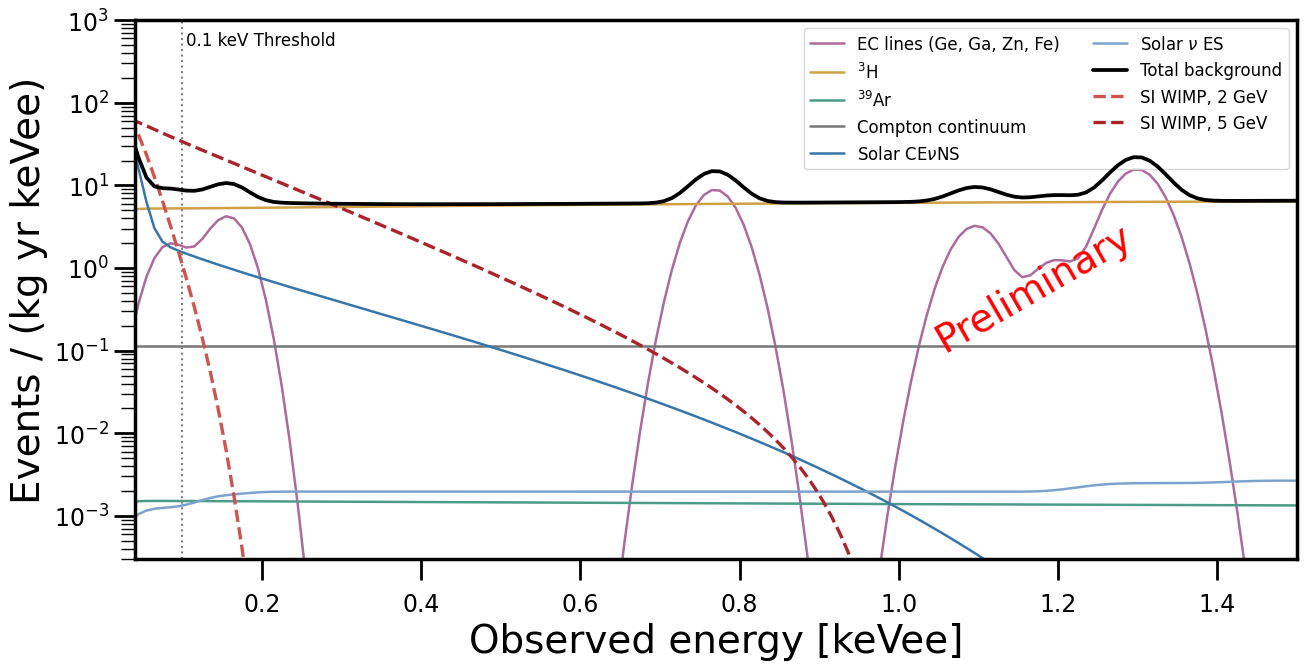

In [33]:
FIGURE_SIZE1 = (15, 7)
SPECTRUM_MASSES_GEV = [2, 5, 1]

maybe_apply_ddp_style()

fig, ax = plt.subplots(figsize=FIGURE_SIZE1)

vals = run["backgrounds"]
ec = sum(
    (np.asarray(vals[f"{scenario}__{name}"]) for name in ("Ge68", "Ga68", "Zn65", "Fe55")),
    np.zeros_like(bin_widths)
)

groups = [
    ("EC lines (Ge, Ga, Zn, Fe)", ec, "#ad6b9c"),
    ("$^3$H", vals[f"{scenario}__H3"], "#d0a048"),
    ("$^{39}$Ar", vals[f"{scenario}__Ar39"], "#4c9c88"),
    ("Compton continuum", vals[f"{scenario}__flat_observed"], "#777777"),
    (r"Solar CE$\nu$NS", vals[f"{scenario}__solar_CEvNS"], "#3876aa"),
    (r"Solar $\nu$ ES", vals[f"{scenario}__solar_ES"], "#7da3cd"),
]

for label, per_bin, color in groups:
    density = np.asarray(per_bin) / bin_widths * days_per_year
    if np.any(density > 0):
        ax.plot(bin_centers, np.where(density > 0, density, np.nan), color=color, linewidth=1.8, label=label)

full = np.asarray(vals[f"{scenario}__Total"]) / bin_widths * days_per_year
ax.plot(bin_centers, np.where(full > 0, full, np.nan), lw=2.7, color="black", label="Total background", zorder=8)

for color, mass in zip(("#cf534f", "#ab232b", "#761727"), SPECTRUM_MASSES_GEV):
    key = f"{scenario}__O1__m{mass:g}"
    if key not in run["signals"]:
        print(f"Missing WIMP spectrum: {key}")
        continue
    density = np.asarray(run["signals"][key]) / bin_widths * days_per_year * SPECTRUM_SIGMA_P_CM2 / sigma_ref
    ax.plot(bin_centers, np.where(density > 0, density, np.nan), color=color, lw=2.4, ls="--", label=f"SI WIMP, {mass:g} GeV")

ax.text(1.3, 0.1, "Preliminary", ha="right", fontsize=LABEL_SIZE/1, color="r", rotation=30)
# ax.set_title(r"Low-Energy Background and WIMP Spectra for $\sigma = 10^{-43}$ cm$^2$", fontsize=LABEL_SIZE-2)
ax.axvline(0.1, color="gray", lw=1.5, ls=":")
ax.text(0.105, 5e2, "0.1 keV Threshold", fontsize=12)
ax.set_xlim(0.04, 1.5)
ax.set_yscale("log")
ax.set_ylim(3e-4, 1e3)
ax.set_xlabel("Observed energy [keVee]", fontsize=LABEL_SIZE)
ax.set_ylabel(r"Events / (kg yr keVee)", fontsize=LABEL_SIZE)
ax.tick_params(which="major", labelsize=TICK_SIZE)
ax.legend(loc="upper right", fontsize=max(9, LEGEND_SIZE - 1), ncol=2)

if SHOW_TITLES:
    ax.set_title("Energy spectra")

save_figure(fig, "01_energy_spectra")
plt.show()

## 6. Plot 2 — neutrino-only best case

Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures_standalone\02_neutrino_best_case.pdf
Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures_standalone\02_neutrino_best_case.png


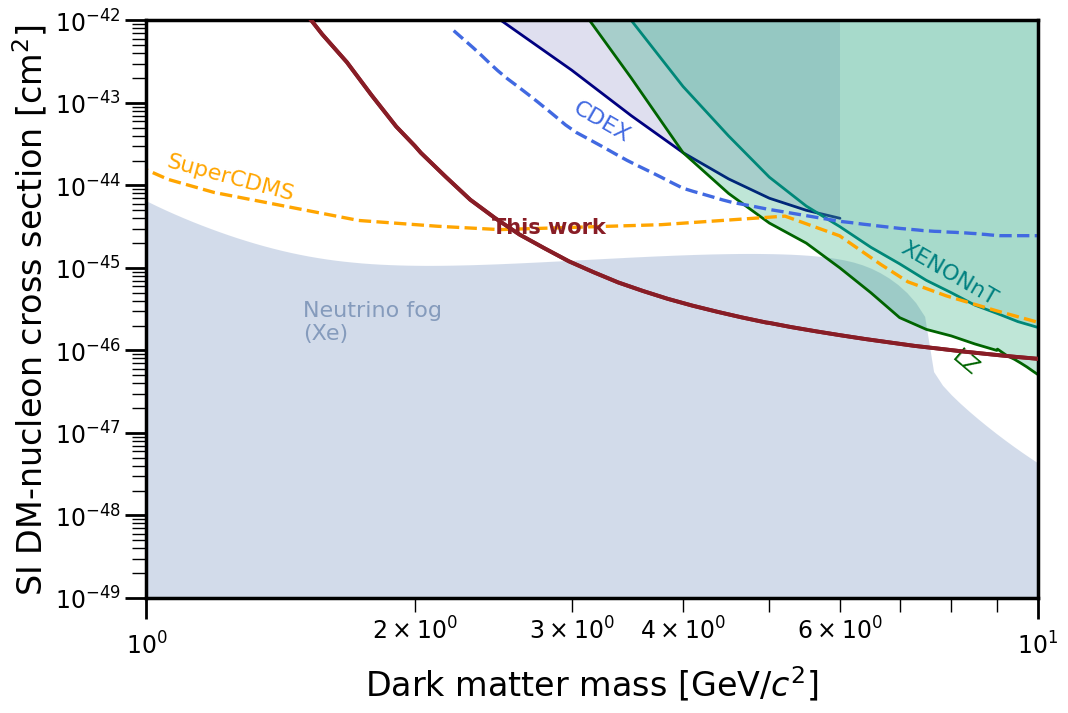

In [34]:
LABEL_SIZE_EXC = LABEL_SIZE-4
maybe_apply_ddp_style()

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
limit_axes(ax, label_size=LABEL_SIZE_EXC, tick_size=TICK_SIZE)

if COMPARISON_MODE == "ddp":
    if DDP_ROOT is None:
        raise RuntimeError("DDP_ROOT is not set or could not be autodetected.")
    draw_ddp_limits(ax, DDP_ROOT, font=ANNOTATION_SIZE, show_fog=SHOW_FOG)

draw_legend_curve(ax, rows, "neutrinos", 0.1, 10.0, label="LEGEND: neutrinos only, 10 t·yr", color="#881d26")

# ax.legend(
#     title="100 eVee · enriched Ge",
#     title_fontsize=max(9, LEGEND_SIZE - 1),
#     fontsize=LEGEND_SIZE,
#     loc="upper right",
#     framealpha=0.93,
# )

draw_legend_curve(
    ax, rows, "neutrinos", 0.1, 10.0,
    label="LEGEND: neutrinos only, 10 t·yr",
    color="#881d26"
)

mark_this_work(ax, ax.lines[-1], fraction=0.45)

if SHOW_TITLES:
    ax.set_title("Neutrino-only benchmark | 100 eVee, 10 t·yr")

save_figure(fig, "02_neutrino_best_case")
plt.show()

## 7. Plot 3 — background comparison

Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures_standalone\03_background_comparison.pdf
Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures_standalone\03_background_comparison.png


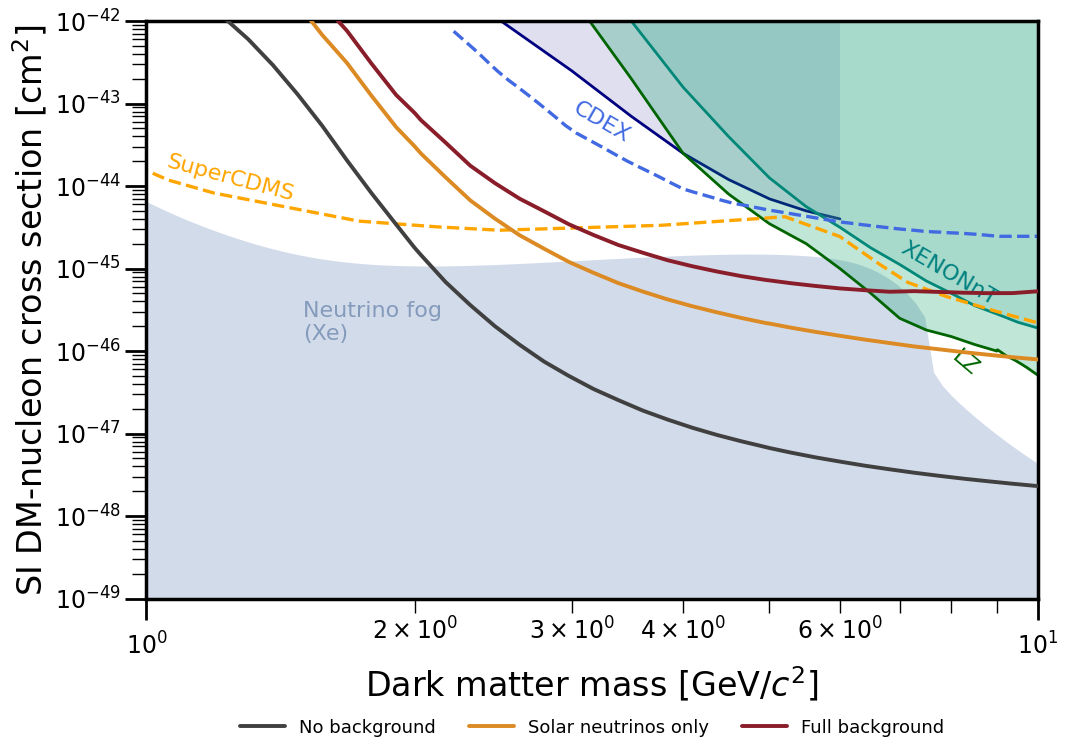

In [35]:
maybe_apply_ddp_style()

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
limit_axes(ax, label_size=LABEL_SIZE_EXC, tick_size=TICK_SIZE)

if COMPARISON_MODE == "ddp":
    if DDP_ROOT is None:
        raise RuntimeError("DDP_ROOT is not set or could not be autodetected.")
    draw_ddp_limits(ax, DDP_ROOT, font=ANNOTATION_SIZE, show_fog=SHOW_FOG)

draw_legend_curve(ax, rows, "none", 0.1, 10.0, label="No background", color="#404040")
draw_legend_curve(ax, rows, "neutrinos", 0.1, 10.0, label="Solar neutrinos only", color="#dc8a23")
draw_legend_curve(ax, rows, "full", 0.1, 10.0, label="Full background", color="#891e2a")

ax.legend(
    title="100 eVee · 10 t·yr · enriched Ge",
    title_fontsize=max(9, LEGEND_SIZE - 1),
    fontsize=LEGEND_SIZE,
    loc="upper right",
    framealpha=0.93,
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    fontsize=13,
    frameon=False,
    handlelength=2.5,
    columnspacing=1.8,
)

# ax.set_xlim(1e-1)

if SHOW_TITLES:
    ax.set_title("Background assumptions | 100 eVee, 10 t·yr")

save_figure(fig, "03_background_comparison")
plt.show()

## 8. Plot 4 — threshold comparison

Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures_standalone\04_threshold_comparison.pdf
Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures_standalone\04_threshold_comparison.png


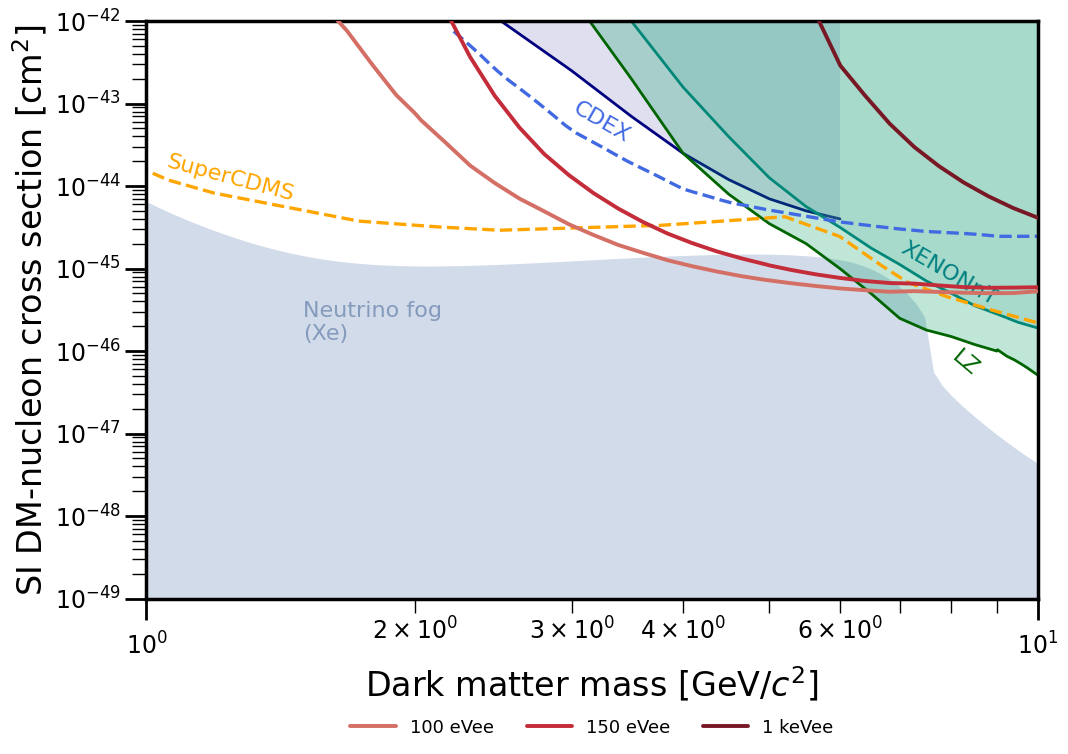

In [36]:
maybe_apply_ddp_style()

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
limit_axes(ax, label_size=LABEL_SIZE_EXC, tick_size=TICK_SIZE)

if COMPARISON_MODE == "ddp":
    if DDP_ROOT is None:
        raise RuntimeError("DDP_ROOT is not set or could not be autodetected.")
    draw_ddp_limits(ax, DDP_ROOT, font=ANNOTATION_SIZE, show_fog=SHOW_FOG)

draw_legend_curve(ax, rows, "full", 0.1, 10.0, label="100 eVee", color="#d46f65")
draw_legend_curve(ax, rows, "full", 0.15, 10.0, label="150 eVee", color="#c42c39")
draw_legend_curve(ax, rows, "full", 1.0, 10.0, label="1 keVee", color="#781825")

ax.legend(
    title="10 t·yr · enriched Ge · full background",
    title_fontsize=max(9, LEGEND_SIZE - 1),
    fontsize=LEGEND_SIZE,
    loc="upper right",
    framealpha=0.93,
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    fontsize=13,
    frameon=False,
    handlelength=2.5,
    columnspacing=1.8,
)

# ax.set_title("Impact of Energy Threshold on WIMP Sensitivity ", fontsize=LABEL_SIZE-6)
# ax.text(2, 1e-48, "Configuration: 10 t·yr · enriched Ge · full background", fontsize=LABEL_SIZE/2)
if SHOW_TITLES:
    ax.set_title("Threshold assumptions | 10 t·yr, full background")

save_figure(fig, "04_threshold_comparison")
plt.show()

## 9. Plot 5 — exposure comparison

Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures_standalone\05_exposure_comparison.pdf
Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures_standalone\05_exposure_comparison.png


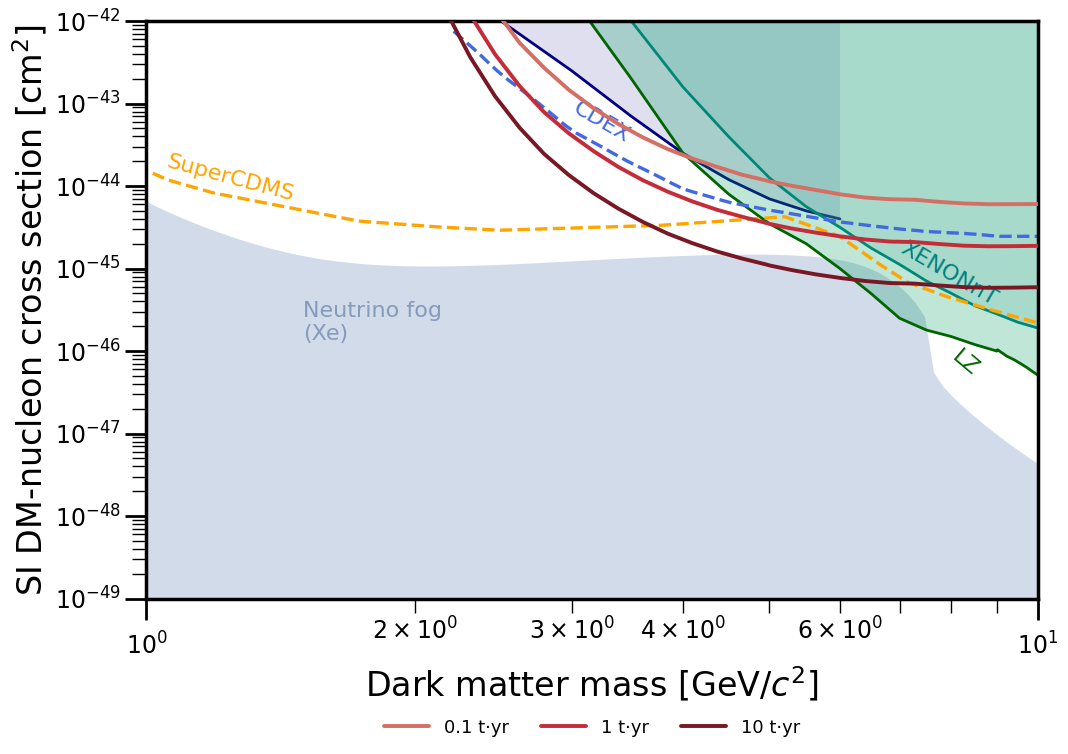

In [37]:
maybe_apply_ddp_style()

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
limit_axes(ax, label_size=LABEL_SIZE_EXC, tick_size=TICK_SIZE)

if COMPARISON_MODE == "ddp":
    if DDP_ROOT is None:
        raise RuntimeError("DDP_ROOT is not set or could not be autodetected.")
    draw_ddp_limits(ax, DDP_ROOT, font=ANNOTATION_SIZE, show_fog=SHOW_FOG)

draw_legend_curve(ax, rows, "full", 0.15, 0.1, label="0.1 t·yr", color="#d46f65")
draw_legend_curve(ax, rows, "full", 0.15, 1.0, label="1 t·yr", color="#c42c39")
draw_legend_curve(ax, rows, "full", 0.15, 10.0, label="10 t·yr", color="#781825")

ax.legend(
    title="150 eVee · enriched Ge · full background",
    title_fontsize=max(9, LEGEND_SIZE - 1),
    fontsize=LEGEND_SIZE,
    loc="upper right",
    framealpha=0.93,
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    fontsize=13,
    frameon=False,
    handlelength=2.5,
    columnspacing=1.8,
)

if SHOW_TITLES:
    ax.set_title("Exposure assumptions | 150 eVee, full background")

save_figure(fig, "05_exposure_comparison")
plt.show()

## 10. Optional quick summary

In [38]:
backgrounds = sorted({r["background"] for r in rows})
thresholds = sorted({float(r["threshold_keVee"]) for r in rows})
exposures = sorted({float(r["exposure_tonne_year"]) for r in rows})
masses = sorted({float(r["mass_GeV"]) for r in rows})

print("Backgrounds:", backgrounds)
print("Thresholds [keVee]:", thresholds)
print("Exposures [t·yr]:", exposures)
print("Mass grid size:", len(masses))
print("Mass range [GeV]:", masses[0], "to", masses[-1])

Backgrounds: ['full', 'neutrinos', 'none']
Thresholds [keVee]: [0.1, 0.15, 1.0]
Exposures [t·yr]: [0.1, 1.0, 10.0]
Mass grid size: 79
Mass range [GeV]: 0.5 to 100.0


## 11. Gaussian Testing

In [41]:
from wimp_legend.detector.resolution import *

In [61]:
gauss = GaussianResolution(0.05)
bins = np.linspace(0, 2, 501)

bins_low = np.linspace(0, 0.2, 501)

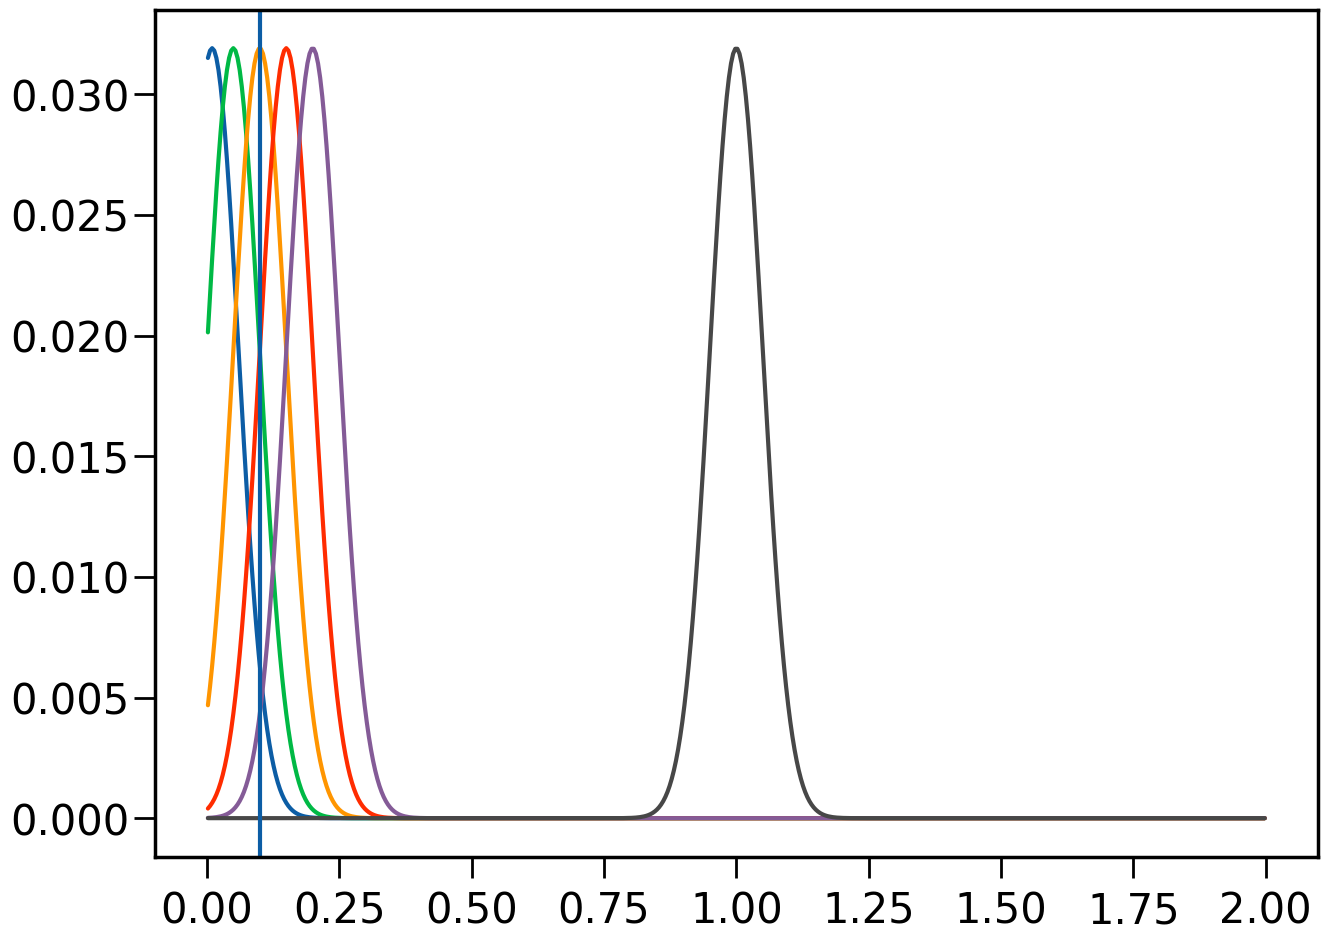

In [62]:
for i in [0.01, 0.05, 0.1, 0.15, 0.2, 1]:

    probs = gauss.bin_probabilities(i, bins)

    plt.plot(0.5*(bins[1:] + bins[:-1]), probs)
plt.axvline(0.1)

In [63]:
0.5*(bins[1:] - bins[:-1])

array([0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002,

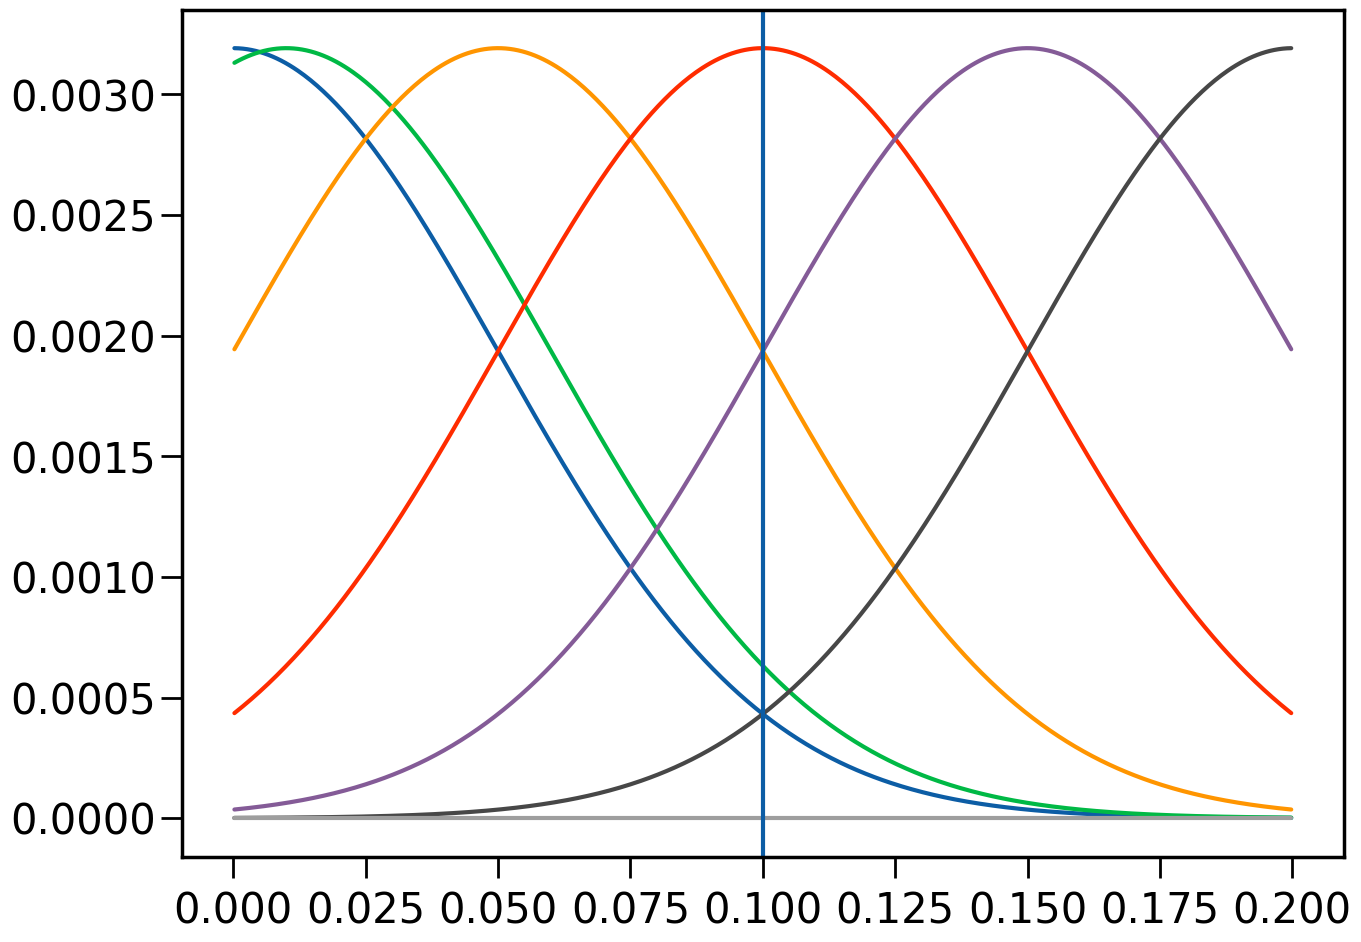

In [66]:
for i in [0, 0.01, 0.05, 0.1, 0.15, 0.2, 1]:

    probs_low = gauss.bin_probabilities(i, bins_low)

    plt.plot(0.5*(bins_low[1:] + bins_low[:-1]), probs_low)
plt.axvline(0.1)